# 04 · KNN

**K-Nearest Neighbors (KNN)** clasifica una reseña según las etiquetas de las *k* reseñas de entrenamiento más parecidas.

- Se usa la **distancia coseno**, la más adecuada para vectores TF-IDF: compara la *dirección* de los vectores (qué palabras
  se usan y con qué peso) sin que importe la longitud de la reseña.
- Se buscan el número de vecinos `k` y el tipo de voto (`uniform`: todos valen igual; `distance`: los más cercanos pesan más).
- KNN **no** tiene parámetro de pesos por clase; `weights="distance"` ayuda un poco a la clase minoritaria (Envío).

**Estructura del notebook** (igual para los 4 modelos, para que la comparación sea justa):
1. Cargar la partición fija (columna `particion`) y el texto preprocesado.
2. Definir el `Pipeline` TF-IDF + clasificador y la malla de hiperparámetros.
3. `GridSearchCV` con validación cruzada estratificada de 5 pliegues **solo sobre entrenamiento** (métrica: F1 macro).
4. Reentrenar con los mejores hiperparámetros y medir tiempos de entrenamiento y predicción.
5. Evaluar en prueba: accuracy, precisión, recall, F1 (macro, ponderado y por clase), matriz de confusión.
6. Guardar predicciones, métricas y el modelo (`joblib`).
7. Análisis de errores y palabras más influyentes.
8. Función para clasificar una reseña nueva.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

import utils
from utils import CLASES, SEMILLA, RESULTADOS, MODELOS

NOMBRE = "KNN"
CLAVE = utils.MODELOS_PROYECTO[NOMBRE]          # nombre de carpeta / archivo
SALIDA = RESULTADOS / CLAVE                       # resultados/{clave}/
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

# Partición fija generada en el notebook 02 (la misma para los 4 modelos)
df, entrenamiento, prueba = utils.cargar_particiones()
X_train, y_train = entrenamiento["texto_procesado"], entrenamiento["etiqueta_reglas"]
X_test, y_test = prueba["texto_procesado"], prueba["etiqueta_reglas"]

print(f"Entrenamiento: {len(X_train)} reseñas | Prueba: {len(X_test)} reseñas")
pd.DataFrame({"entrenamiento": y_train.value_counts(), "prueba": y_test.value_counts()}).reindex(CLASES)

Entrenamiento: 11860 reseñas | Prueba: 2966 reseñas


,entrenamiento,prueba
etiqueta_reglas,,
Envío,274,68
Producto,4613,1154
Sentimiento,6973,1744


## 1. Pipeline y malla de hiperparámetros

TF-IDF (parámetros comunes de `utils.crear_vectorizador()`) + `KNeighborsClassifier(metric="cosine", algorithm="brute")`.

In [2]:
pipeline = Pipeline([
    ("tfidf", utils.crear_vectorizador()),
    ("clf", KNeighborsClassifier(metric="cosine", algorithm="brute")),
])
malla = {
    "clf__n_neighbors": [3, 5, 7, 11, 15, 21, 31],
    "clf__weights": ["uniform", "distance"],
}
print("Combinaciones a evaluar:", np.prod([len(v) for v in malla.values()]), "x 5 pliegues")

Combinaciones a evaluar: 14 x 5 pliegues


## 2. Búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)

`GridSearchCV` prueba todas las combinaciones con **validación cruzada estratificada de 5 pliegues** (`random_state=42`) usando
**F1 macro** como criterio (también registra accuracy). Como el TF-IDF está dentro del `Pipeline`, en cada pliegue el vocabulario
se aprende solo con los datos de entrenamiento de ese pliegue: **no hay fuga de información**. El conjunto de prueba no se toca aquí.

In [3]:
busqueda, tiempo_busqueda = utils.buscar_hiperparametros(pipeline, malla, X_train, y_train)
print(f"Tiempo total de la búsqueda: {tiempo_busqueda:.1f} s")
print("Mejores hiperparámetros:", busqueda.best_params_)

cv = utils.resumen_cv(busqueda)
print(f"F1 macro en CV (5 pliegues): {cv['cv_f1_macro_media']:.4f} ± {cv['cv_f1_macro_std']:.4f}")
print(f"Accuracy en CV (5 pliegues): {cv['cv_accuracy_media']:.4f} ± {cv['cv_accuracy_std']:.4f}")

mejores, todas = utils.tabla_busqueda(busqueda)
todas.to_csv(SALIDA / "busqueda_hiperparametros.csv", index=False, encoding="utf-8-sig")
mejores.round(4)

Tiempo total de la búsqueda: 44.8 s
Mejores hiperparámetros: {'clf__n_neighbors': 5, 'clf__weights': 'uniform'}
F1 macro en CV (5 pliegues): 0.5720 ± 0.0270
Accuracy en CV (5 pliegues): 0.6971 ± 0.0065


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy,std_test_accuracy,mean_fit_time,rank_test_f1_macro
0,"{'clf__n_neighbors': 5, 'clf__weights': 'uniform'}",0.5720,0.0270,0.6971,0.0065,4.1616,1
1,"{'clf__n_neighbors': 7, 'clf__weights': 'uniform'}",0.5695,0.0263,0.7072,0.0046,3.7599,2
2,"{'clf__n_neighbors': 15, 'clf__weights': 'uniform'}",0.5695,0.0405,0.7253,0.0088,3.5355,3
3,"{'clf__n_neighbors': 15, 'clf__weights': 'distance'}",0.5692,0.0398,0.7267,0.0096,3.8217,4
4,"{'clf__n_neighbors': 7, 'clf__weights': 'distance'}",0.5688,0.0244,0.7073,0.0048,4.3260,5
5,"{'clf__n_neighbors': 11, 'clf__weights': 'uniform'}",0.5672,0.0350,0.7175,0.0047,3.8193,6
6,"{'clf__n_neighbors': 21, 'clf__weights': 'uniform'}",0.5639,0.0360,0.7299,0.0076,4.2337,7
7,"{'clf__n_neighbors': 21, 'clf__weights': 'distance'}",0.5635,0.0370,0.7297,0.0092,3.0401,8
8,"{'clf__n_neighbors': 11, 'clf__weights': 'distance'}",0.5632,0.0331,0.7180,0.0041,3.1726,9
9,"{'clf__n_neighbors': 5, 'clf__weights': 'distance'}",0.5624,0.0386,0.6978,0.0071,3.5447,10


## 3. Reentrenar con los mejores hiperparámetros y medir tiempos

Se clona el mejor pipeline y se entrena de nuevo con **todo** el conjunto de entrenamiento, midiendo con `time.perf_counter()`:
- **Tiempo de entrenamiento:** ajuste del TF-IDF + clasificador.
- **Tiempo de predicción:** clasificar todas las reseñas de prueba.

Para que la comparación entre modelos sea justa, antes de medir se cierran los procesos auxiliares que dejó `GridSearchCV`
y la medición se repite **3 veces**, reportando la **mediana** (las predicciones son idénticas en cada repetición).

In [4]:
modelo = clone(busqueda.best_estimator_)
modelo, y_pred, t_entrenamiento, t_prediccion = utils.medir_entrenamiento_y_prediccion(modelo, X_train, y_train, X_test)
print(f"Tiempo de entrenamiento (mediana de 3): {t_entrenamiento:.3f} s")
print(f"Tiempo de predicción ({len(X_test)} reseñas): {t_prediccion:.3f} s "
      f"({1000 * t_prediccion / len(X_test):.3f} ms por reseña)")

Tiempo de entrenamiento (mediana de 3): 1.174 s
Tiempo de predicción (2966 reseñas): 0.710 s (0.239 ms por reseña)


## 4. Evaluación en el conjunto de prueba

In [5]:
metricas = utils.calcular_metricas(y_test, y_pred)
metricas.update(cv)
metricas.update({
    "tiempo_busqueda_s": tiempo_busqueda,
    "tiempo_entrenamiento_s": t_entrenamiento,
    "tiempo_prediccion_s": t_prediccion,
    "mejores_hiperparametros": {k: str(v) for k, v in busqueda.best_params_.items()},
})
metricas = utils.guardar_metricas(NOMBRE, metricas, SALIDA)
reporte = utils.guardar_reporte(NOMBRE, y_test, y_pred, metricas, SALIDA)
print(reporte)
print(f"Accuracy: {metricas['accuracy']:.4f} | F1 macro: {metricas['f1_macro']:.4f} | "
      f"F1 ponderado: {metricas['f1_ponderado']:.4f} | Errores: {metricas['n_errores']} de {metricas['n_prueba']}")

              precision    recall  f1-score   support

       Envío     0.5769    0.2206    0.3191        68
    Producto     0.6869    0.4905    0.5723      1154
 Sentimiento     0.7155    0.8681    0.7845      1744

    accuracy                         0.7063      2966
   macro avg     0.6598    0.5264    0.5586      2966
weighted avg     0.7012    0.7063    0.6912      2966

Accuracy: 0.7063 | F1 macro: 0.5586 | F1 ponderado: 0.6912 | Errores: 871 de 2966


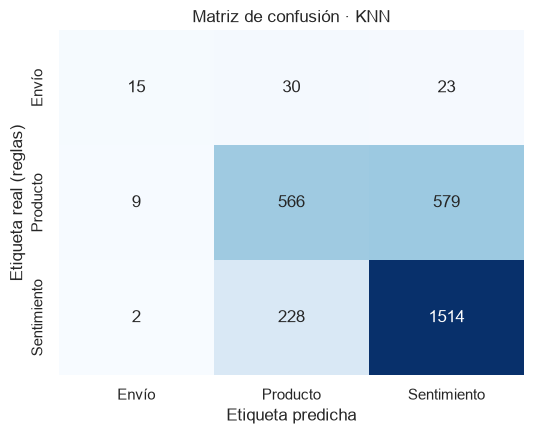

,pred_Envío,pred_Producto,pred_Sentimiento
real_Envío,15,30,23
real_Producto,9,566,579
real_Sentimiento,2,228,1514


In [6]:
matriz = utils.graficar_matriz_confusion(y_test, y_pred, f"Matriz de confusión · {NOMBRE}", SALIDA)
plt.show()
matriz

## 5. Guardar predicciones y modelo

- `predicciones_prueba.csv`: texto, estrellas, etiqueta real (reglas), etiqueta predicha, si acertó y la confianza por clase.
- `modelos/<modelo>.joblib`: el pipeline completo (TF-IDF + clasificador), listo para clasificar texto preprocesado.
- `mejores_hiperparametros.json`.

In [7]:
predicciones = utils.guardar_predicciones(prueba, y_pred, modelo, SALIDA)
joblib.dump(modelo, MODELOS / f"{CLAVE}.joblib")
with open(SALIDA / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(metricas["mejores_hiperparametros"], f, ensure_ascii=False, indent=2)
print("Guardados:", (SALIDA / "predicciones_prueba.csv").relative_to(utils.BASE), "|",
      (MODELOS / f"{CLAVE}.joblib").relative_to(utils.BASE))
predicciones.head()

Guardados: resultados\knn\predicciones_prueba.csv | modelos\knn.joblib


,id,text,rating,polarity,etiqueta_real,etiqueta_predicha,correcta,confianza_Envío,confianza_Producto,confianza_Sentimiento
0,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B004OF968O_1493389988000,"Not for me..... I was not expecting much, but for me, these bags are a joke. I can't believe so many are still available, but impossible to find out who actually makes them. I wanted to make a s...",1.0,negative,Sentimiento,Sentimiento,True,0.0,0.4,0.6
1,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B00P9UC004_1521055721867,"Very small size. These are so small everything falls off. Too small for baseball caps, they just fall off. The pictures do not show the scale. Good if you want to hang a few rubber bands on hoo...",1.0,negative,Producto,Sentimiento,False,0.0,0.4,0.6
2,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B081B65WT8_1591466996903,Did not work for me. I always have a problem when cooking pasta sauce on my glass stove top. I purchased a counter top induction burner and a new SS 16 qt stock pot along with this item. $$$$$ s...,2.0,negative,Producto,Producto,True,0.0,0.6,0.4
3,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08G7Y67GH_1617298313281,UPDATE. Originally said this was a good deal....does the job.....bit after only three times with an egg one of the wires broke and hangs loose so now the slicer is useless. NOT a good deal and no...,1.0,negative,Producto,Sentimiento,False,0.0,0.4,0.6
4,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08NVKYLGV_1521054740535,"Should have sent it back...!!. I like the product just fine, but almost returned it because the large product label was so hard to remove, I ended up scratching the plastic. Now every time the lig...",2.0,negative,Producto,Sentimiento,False,0.0,0.4,0.6


## 6. Análisis de errores

### 6.1 ¿Qué confusiones son más frecuentes? Ejemplos reales

In [8]:
conteo_errores, ejemplos = utils.ejemplos_errores(predicciones, SALIDA, n_por_tipo=3)
display(conteo_errores)
for (real, pred), grupo in ejemplos.groupby(["etiqueta_real", "etiqueta_predicha"], sort=False):
    print(f"\n--- Real: {real}  ->  Predicha: {pred} ---")
    for _, fila in grupo.iterrows():
        print(f"  [{int(fila['rating'])}★] {fila['text']}")

,etiqueta_real,etiqueta_predicha,n_errores
0,Producto,Sentimiento,579
1,Sentimiento,Producto,228
2,Envío,Producto,30
3,Envío,Sentimiento,23
4,Producto,Envío,9
5,Sentimiento,Envío,2



--- Real: Producto  ->  Predicha: Sentimiento ---
  [3★] Wouldn't purchase again.. It's very thin. I'm afraid that as soon as I wash this it's going to fall apart.  And the purple wasn't very good.  I was expecting a darker purple.  This was more of a bright purple.  Not at all what I was going for.
  [2★] Heavier weight than many but shop around.. Not bad quality ( it was the #1 rated ) but the one I got from Amazon kept grabbing and ripping the paper off the cans. I think it may have been defective so I sent it back and bought a different brand. This model is heavier weight than many of the others a
  [1★] hard, small and short. I'm 5'2" and I .... hard, small and short. I'm 5'2&#34; and I hang off it on both ends. no padding and no back support. I keep telling myself i'm done buying from china because nothing is ever right and its all cheap. NOT FOR A WEAK OR ELDERLY PERSON, HARD TO OPEN, HARD TO CLO

--- Real: Sentimiento  ->  Predicha: Producto ---
  [3★] This is an excellent spo

### 6.2 ¿Se clasifican peor las reseñas de 3 estrellas (neutral)?

In [9]:
por_polaridad = utils.desempeno_por_polaridad(predicciones, SALIDA)
por_polaridad.round(4)

,polaridad,n,accuracy,f1_macro
0,negative,955,0.6325,0.5386
1,neutral,1022,0.6380,0.5200
2,positive,989,0.8483,0.5203


### 6.3 ¿Por qué decidió así? Vecinos más cercanos

KNN no aprende pesos por palabra (es un método *basado en instancias*), así que no tiene "palabras más influyentes".
En su lugar mostramos, para una reseña de prueba de la clase **Envío**, cuáles fueron sus vecinos más cercanos en entrenamiento:
así se ve directamente en qué se basa la decisión.

In [10]:
tfidf, knn = modelo.named_steps["tfidf"], modelo.named_steps["clf"]
ejemplo = prueba[prueba["etiqueta_reglas"] == "Envío"].sample(1, random_state=SEMILLA).iloc[0]
print("Reseña de prueba:", ejemplo["text"][:250].replace("<br />", " "))
print("Etiqueta real:", ejemplo["etiqueta_reglas"], "| Predicha:", modelo.predict([ejemplo["texto_procesado"]])[0])

distancias, indices = knn.kneighbors(tfidf.transform([ejemplo["texto_procesado"]]), n_neighbors=5)
vecinos = entrenamiento.iloc[indices[0]][["etiqueta_reglas", "text"]].copy()
vecinos.insert(0, "distancia_coseno", distancias[0].round(3))
vecinos["text"] = vecinos["text"].str.replace("<br />", " ").str.slice(0, 160)
vecinos

Reseña de prueba: 3 stars, but you might receive a better one than me. [[VIDEOID:1ec2c5c03f18c09cfcc338eaa9825c45]] The stainless steel is nicely polished and I love the 40L size! However, on mine the lid does not shut flush in the back. Then, mine came with
Etiqueta real: Envío | Predicha: Producto


,distancia_coseno,etiqueta_reglas,text
1508,0.711,Producto,"Not what I was expecting at all, sizes are way off…. [[VIDEOID:8d122d6f9b610f63f2400e5b5263af4b]] I don’t like to give 1 star reviews, but the description shoul"
2243,0.738,Envío,This is so cute! However mine came broken! .... This is so cute ! However mine came broken ! NO head ! Ugh
1512,0.749,Sentimiento,Just can’t find the sweet spot…. [[VIDEOID:2f1257edf8322b874f09e9bc085abd57]] Just can’t seem to find the right shape. The sides sag and not fluffy enough with
1507,0.756,Producto,"Not what I was expecting!. [[VIDEOID:37111c30c0ba2960d712bcafe5599b48]] Not very absorbent. Fine threads on bottom, not durable Didn’t feel like soft cotton Tr"
1518,0.766,Sentimiento,Cheap and Thin!. [[VIDEOID:a53a14db182a45c90bd26533d2ffb474]] Not too impressed. Thin and not doubled bottom. Feels pretty cheap. Can’t see the handle joints


## 7. Clasificar una reseña nueva

La reseña se preprocesa exactamente igual que en el entrenamiento (`utils.preprocesar_texto`) y luego pasa por el pipeline
(TF-IDF + clasificador).

In [11]:
def clasificar_texto(texto):
    procesado = utils.preprocesar_texto(texto)
    confianzas, tipo = utils.puntajes_confianza(modelo, [procesado])
    etiqueta = modelo.predict([procesado])[0]
    detalle = {c: round(float(p), 3) for c, p in zip(modelo.classes_, confianzas[0])}
    return etiqueta, detalle

for resena in ["The box arrived crushed and two glasses were broken.",
               "The blender stopped working after a week, the motor smells like burning.",
               "Absolutely love these towels, they are soft and beautiful!"]:
    etiqueta, detalle = clasificar_texto(resena)
    print(f"{etiqueta:12s} {detalle}  <-  {resena}")

Sentimiento  {'Envío': 0.0, 'Producto': 0.4, 'Sentimiento': 0.6}  <-  The box arrived crushed and two glasses were broken.
Producto     {'Envío': 0.0, 'Producto': 0.8, 'Sentimiento': 0.2}  <-  The blender stopped working after a week, the motor smells like burning.
Sentimiento  {'Envío': 0.0, 'Producto': 0.0, 'Sentimiento': 1.0}  <-  Absolutely love these towels, they are soft and beautiful!
